<a href="https://colab.research.google.com/github/Pratyush2722/AI_Document_Assistant/blob/main/Research_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Show continuous consensus works and link to eigenvalue theory**

=== Continuous Consensus Simulation ===
Number of agents: 4
Simulation time: 5.0 s, dt = 0.001
Initial states: [ 6.2945  8.1158 -7.4603  8.2675]
Average initial state: 3.8044
Final states: [3.80437613 3.8043751  3.80437404 3.80437473]
Average final state: 3.8044
Final disagreement V(T): 1.146046e-12


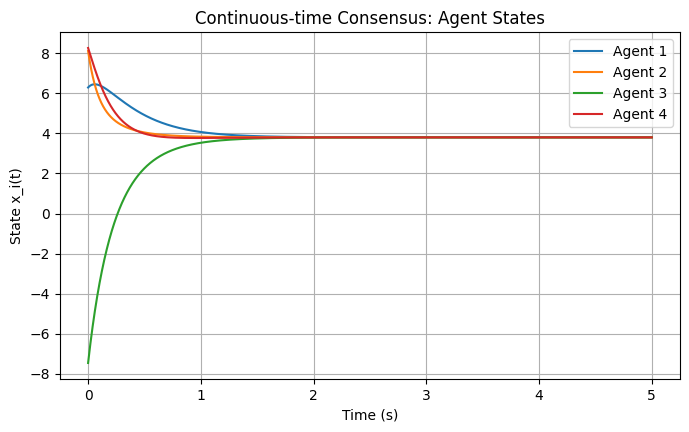

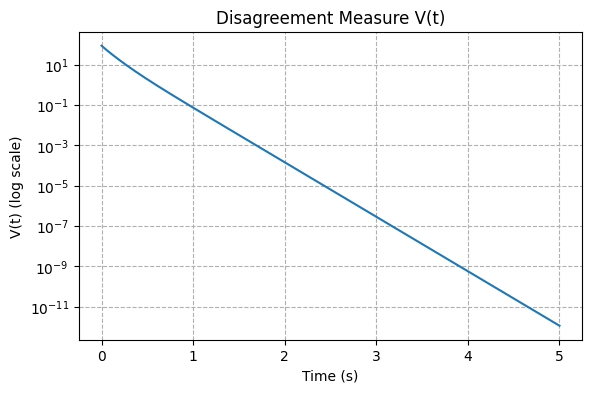

In [ ]:
# ================================
# Continuous Consensus Simulation
# ================================

import numpy as np
import matplotlib.pyplot as plt

# ----- Simulation parameters -----
dt = 0.001      # integration timestep (s)
T = 5.0         # total simulation time (s)
steps = int(T / dt)

# ----- Network Laplacian (example from paper) -----
L = np.array([[ 3.4, -3.4,  0.0,  0.0],
              [-3.4,  9.8, -2.1, -4.3],
              [ 0.0, -2.1,  3.2, -1.1],
              [ 0.0, -4.3, -1.1,  5.4]])

n = L.shape[0]

# ----- Initial states (example) -----
x0 = np.array([6.2945, 8.1158, -7.4603, 8.2675], dtype=float)

# ----- Pre-allocations -----
X = np.zeros((steps+1, n))
time = np.linspace(0, T, steps+1)
X[0, :] = x0.copy()

# Precompute Kn = I - (1/n) * 11^T (for Lyapunov V)
In = np.eye(n)
ones = np.ones((n,1))
Kn = In - (1.0/n) * (ones @ ones.T)

V = np.zeros(steps+1)  # Lyapunov candidate
V[0] = 0.5 * X[0].dot(Kn).dot(X[0])

# ----- Euler integration of xdot = -L x -----
for k in range(steps):
    x = X[k]
    u = -L.dot(x)        # consensus law
    x_next = x + dt * u  # Euler step
    X[k+1] = x_next
    V[k+1] = 0.5 * x_next.dot(Kn).dot(x_next)

# ----- Results -----
final_states = X[-1]
avg_initial = np.mean(x0)
avg_final = np.mean(final_states)

print("=== Continuous Consensus Simulation ===")
print(f"Number of agents: {n}")
print(f"Simulation time: {T} s, dt = {dt}")
print(f"Initial states: {x0}")
print(f"Average initial state: {avg_initial:.4f}")
print(f"Final states: {final_states}")
print(f"Average final state: {avg_final:.4f}")
print(f"Final disagreement V(T): {V[-1]:.6e}")

# ----- Plot 1: agent states -----
plt.figure(figsize=(8,4.5))
for i in range(n):
    plt.plot(time, X[:, i], label=f"Agent {i+1}")
plt.xlabel("Time (s)")
plt.ylabel("State x_i(t)")
plt.title("Continuous-time Consensus: Agent States")
plt.legend()
plt.grid(True)
plt.show()

# ----- Plot 2: Lyapunov candidate V(t) -----
plt.figure(figsize=(6.5,4))
plt.plot(time, V)
plt.yscale('log')
plt.xlabel("Time (s)")
plt.ylabel("V(t) (log scale)")
plt.title("Disagreement Measure V(t)")
plt.grid(True, which="both", ls="--")
plt.show()


Laplacian eigenvalues: [-8.07019111e-16  3.10289805e+00  5.23022528e+00  1.34668767e+01]
Theoretical lambda2: 3.102898054233241
Observed exponential decay rate (approx): 6.4505
Theoretical bound on decay rate (2*lambda2): 6.2058


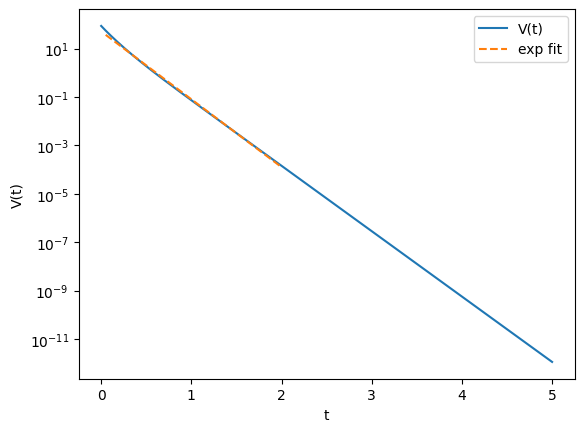

In [ ]:
import numpy as np

# assume L, time, V (V>0) are available from your simulation
eigvals = np.linalg.eigvalsh(L)        # sorted ascending
lambda2 = eigvals[1]                   # second smallest (index 1)
print("Laplacian eigenvalues:", eigvals)
print("Theoretical lambda2:", lambda2)

# pick time window to fit (avoid initial transient or numerical noise near zero)
t_start = 0.05   # seconds
t_end   = 2.0    # seconds (choose a range where V is well above numerical zero)
mask = (time >= t_start) & (time <= t_end)
tt = time[mask]
VV = V[mask]

# linear fit to log(V)
logVV = np.log(VV + 1e-30)   # tiny offset to be safe numerically
slope, intercept = np.polyfit(tt, logVV, 1)
observed_rate = -slope       # because log(V) ~ log(V0) - rate * t
print(f"Observed exponential decay rate (approx): {observed_rate:.4f}")

# Theoretical lower bound rate:
theory_rate = 2 * lambda2
print(f"Theoretical bound on decay rate (2*lambda2): {theory_rate:.4f}")

# Optional: plot the fitted exponential on top of V
import matplotlib.pyplot as plt
plt.figure()
plt.plot(time, V, label='V(t)')
plt.plot(tt, np.exp(intercept + slope*tt), '--', label='exp fit')
plt.yscale('log')
plt.xlabel('t')
plt.ylabel('V(t)')
plt.legend()
plt.show()


In [ ]:
# try different fitting windows
for (t0, t1) in [(0.01,1.0), (0.05,2.0), (0.1,3.0)]:
    mask = (time >= t0) & (time <= t1)
    slope, intercept = np.polyfit(time[mask], np.log(V[mask] + 1e-30), 1)
    print(f"fit window [{t0},{t1}] -> observed rate = {-slope:.4f}")

# try smaller dt (re-run sim with dt=0.0005) and compare rates (you would re-run whole sim)


fit window [0.01,1.0] -> observed rate = 6.9338
fit window [0.05,2.0] -> observed rate = 6.4505
fit window [0.1,3.0] -> observed rate = 6.3145


***Static event-triggered consensus coding***

Static event-triggered results:
 Agent 1: triggers = 45, avg inter-event = 0.1103 s
 Agent 2: triggers = 28, avg inter-event = 0.1770 s
 Agent 3: triggers = 44, avg inter-event = 0.1136 s
 Agent 4: triggers = 25, avg inter-event = 0.1992 s


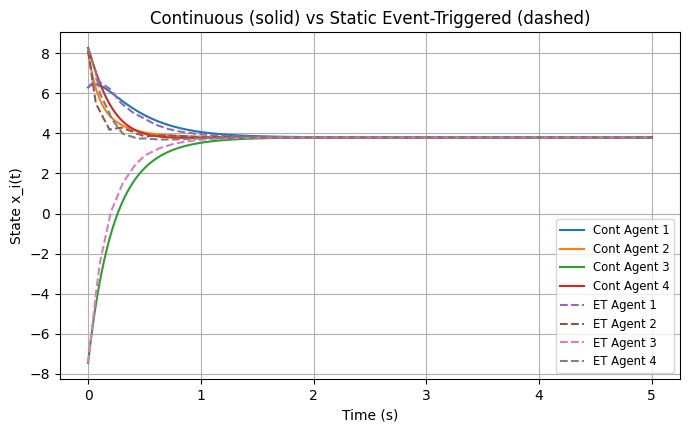

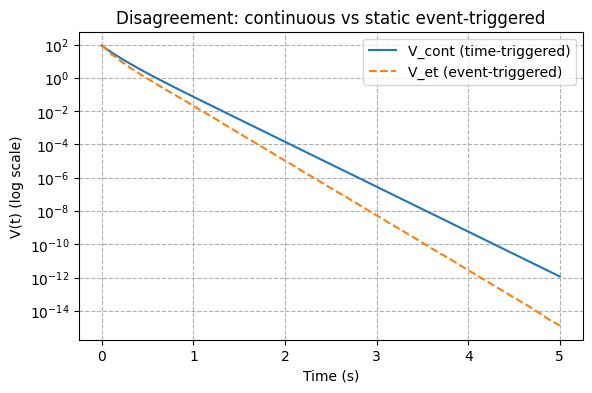

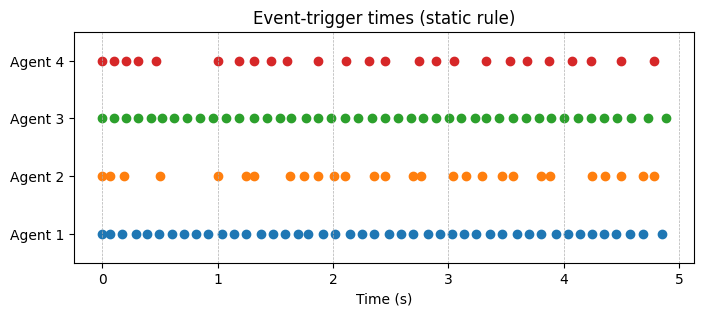

In [1]:
# ============================================================
# Static Event-Triggered Consensus vs Continuous Consensus
# ============================================================
# Aim:
#   Compare baseline continuous-time consensus with static event-triggered consensus.
#   Show that agents still reach agreement, but with fewer communications.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------------- Simulation parameters ----------------
dt = 0.001      # integration timestep (s)
T = 5.0         # total simulation time (s)
steps = int(T / dt)
time = np.linspace(0, T, steps+1)

# ---------------- Network Laplacian ----------------
L = np.array([[ 3.4, -3.4,  0.0,  0.0],
              [-3.4,  9.8, -2.1, -4.3],
              [ 0.0, -2.1,  3.2, -1.1],
              [ 0.0, -4.3, -1.1,  5.4]])
n = L.shape[0]
Lii = np.diag(L).copy()

# ---------------- Initial states ----------------
x0 = np.array([6.2945, 8.1158, -7.4603, 8.2675], dtype=float)

# ============================================================
# Continuous consensus (baseline)
# ============================================================
X_cont = np.zeros((steps+1, n))
X_cont[0] = x0.copy()
for k in range(steps):
    x = X_cont[k]
    u = -L.dot(x)
    X_cont[k+1] = x + dt * u

# Disagreement measure V(t)
V_cont = 0.5 * np.sum((X_cont - X_cont.mean(axis=1, keepdims=True))**2, axis=1)

# ============================================================
# Static Event-triggered consensus
# ============================================================
sigma = 0.5          # sigma_i (same for all agents here)
X_et = np.zeros((steps+1, n))
X_et[0] = x0.copy()
x_hat = x0.copy()    # last broadcast values
trigger_times = [[] for _ in range(n)]
for i in range(n):
    trigger_times[i].append(0.0)  # all agents trigger at t=0

V_et = np.zeros(steps+1)
V_et[0] = 0.5 * np.sum((x0 - np.mean(x0))**2)

for k in range(steps):
    t = time[k]
    x = X_et[k].copy()
    u = -L.dot(x_hat)
    x_next = x + dt * u
    X_et[k+1] = x_next

    # Local error
    e = x_hat - x_next

    # Compute qhat_i
    qhat = np.zeros(n)
    for i in range(n):
        s = 0.0
        for j in range(n):
            dij = x_hat[j] - x_hat[i]
            s += L[i,j] * (dij**2)
        qhat[i] = max(-0.5 * s, 0.0)

    # Triggering condition
    for i in range(n):
        rhs = (sigma / (2.0 * Lii[i])) * qhat[i] if Lii[i] > 0 else 0.0
        if e[i]**2 > rhs + 1e-15:  # trigger
            x_hat[i] = x_next[i]
            trigger_times[i].append(t + dt)

    V_et[k+1] = 0.5 * np.sum((x_next - np.mean(x_next))**2)

# ============================================================
# Results: trigger statistics
# ============================================================
trigger_counts = [len(trigger_times[i]) for i in range(n)]
avg_inter_event = []
for i in range(n):
    times = np.array(trigger_times[i])
    diffs = np.diff(times) if len(times) > 1 else []
    avg_inter_event.append(np.mean(diffs) if len(diffs) > 0 else np.nan)

print("Static event-triggered results:")
for i in range(n):
    print(f" Agent {i+1}: triggers = {trigger_counts[i]}, "
          f"avg inter-event = {avg_inter_event[i]:.4f} s")

# ============================================================
# Plots
# ============================================================

# Plot 1: agent trajectories
plt.figure(figsize=(8,4.5))
for i in range(n):
    plt.plot(time, X_cont[:, i], label=f"Cont Agent {i+1}")
for i in range(n):
    plt.plot(time, X_et[:, i], linestyle='--', label=f"ET Agent {i+1}")
plt.xlabel("Time (s)")
plt.ylabel("State x_i(t)")
plt.title("Continuous (solid) vs Static Event-Triggered (dashed)")
plt.legend(fontsize='small', loc='best')
plt.grid(True)
plt.show()

# Plot 2: Disagreement measure
plt.figure(figsize=(6.5,4))
plt.plot(time, V_cont, label='V_cont (time-triggered)')
plt.plot(time, V_et, linestyle='--', label='V_et (event-triggered)')
plt.yscale('log')
plt.xlabel("Time (s)")
plt.ylabel("V(t) (log scale)")
plt.title("Disagreement: continuous vs static event-triggered")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

# Plot 3: event times (raster)
plt.figure(figsize=(8,3))
for i in range(n):
    times = trigger_times[i]
    y = np.ones_like(times) * (i+1)
    plt.scatter(times, y, marker='o')
plt.xlabel("Time (s)")
plt.yticks(range(1, n+1), [f"Agent {i}" for i in range(1, n+1)])
plt.title("Event-trigger times (static rule)")
plt.grid(True, axis='x', ls='--', lw=0.5)
plt.ylim(0.5, n+0.5)
plt.show()


**Dynamic Event-Triggered Consensus**




Dynamic ET: triggers per agent and avg inter-event time (s):
 Agent 1: 6 triggers, avg inter-event = 0.8666 s
 Agent 2: 7 triggers, avg inter-event = 0.7375 s
 Agent 3: 7 triggers, avg inter-event = 0.7375 s
 Agent 4: 6 triggers, avg inter-event = 0.8666 s


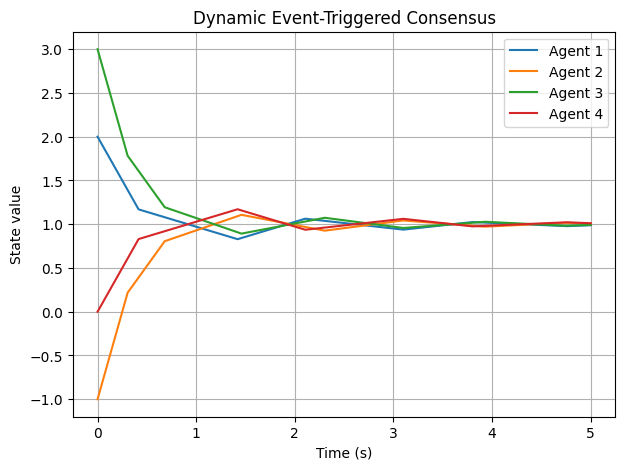

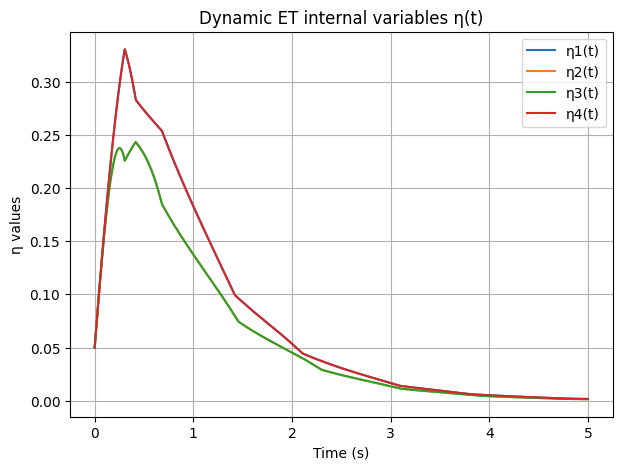

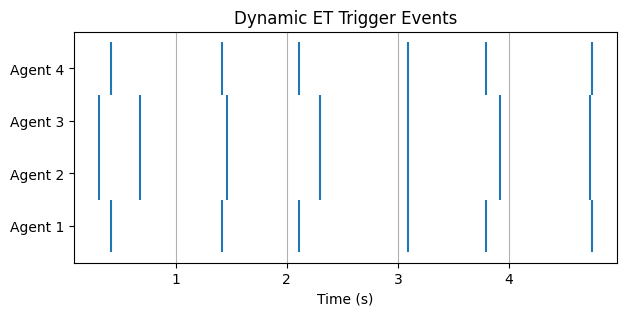

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ===== Parameters =====
n = 4                           # number of agents
T = 5.0                         # total simulation time
dt = 0.001                      # step size
steps = int(T/dt)
sigma = 0.5                     # static ET parameter
beta = 1.0                      # decay rate for eta
xi = 0.5                        # scaling parameter for eta
theta = 0.5                     # dynamic threshold param
eta0 = 0.05                     # initial eta value

# Graph (ring topology)
L = np.array([[ 2, -1, -1,  0],
              [-1,  2,  0, -1],
              [-1,  0,  2, -1],
              [ 0, -1, -1,  2]])

# ===== Initial conditions =====
x = np.array([2.0, -1.0, 3.0, 0.0])   # actual states
x_hat = x.copy()                      # last broadcast values
eta = np.ones(n) * eta0               # dynamic variables
triggers = [[] for _ in range(n)]     # store trigger times
states = [x.copy()]
etas = [eta.copy()]
time = [0]

# ===== Simulation =====
for k in range(1, steps+1):
    t = k*dt

    # Compute disagreement term q_i for each agent
    q = np.zeros(n)
    for i in range(n):
        for j in range(n):
            q[i] += -L[i,j] * (x_hat[i] - x_hat[j])**2

    # Compute errors
    e = x_hat - x

    # Triggering condition (dynamic)
    for i in range(n):
        cond = theta * (L[i,i]*e[i]**2 - (sigma/2)*q[i]) - eta[i]
        if cond > 0:
            # Broadcast event
            x_hat[i] = x[i]
            triggers[i].append(t)

    # Update system state with last broadcast controls
    dx = -L @ x_hat
    x = x + dt*dx

    # Update eta dynamics
    d_eta = -beta*eta + xi*((sigma/2)*q - L.diagonal()*e**2)
    eta = eta + dt*d_eta

    # Record history
    states.append(x.copy())
    etas.append(eta.copy())
    time.append(t)

# ===== Results =====
states = np.array(states)
etas = np.array(etas)

print("Dynamic ET: triggers per agent and avg inter-event time (s):")
for i in range(n):
    times = np.diff(triggers[i]) if len(triggers[i])>1 else []
    avg_ie = np.mean(times) if len(times)>0 else None
    print(f" Agent {i+1}: {len(triggers[i])} triggers, avg inter-event = {avg_ie:.4f} s" if avg_ie else
          f" Agent {i+1}: {len(triggers[i])} triggers, only one or zero events")

# ===== Plot trajectories =====
plt.figure(figsize=(7,5))
for i in range(n):
    plt.plot(time, states[:,i], label=f"Agent {i+1}")
plt.xlabel("Time (s)")
plt.ylabel("State value")
plt.title("Dynamic Event-Triggered Consensus")
plt.legend()
plt.grid(True)
plt.show()

# ===== Plot eta dynamics =====
plt.figure(figsize=(7,5))
for i in range(n):
    plt.plot(time, etas[:,i], label=f"η{i+1}(t)")
plt.xlabel("Time (s)")
plt.ylabel("η values")
plt.title("Dynamic ET internal variables η(t)")
plt.legend()
plt.grid(True)
plt.show()

# ===== Raster of trigger times =====
plt.figure(figsize=(7,3))
for i in range(n):
    plt.vlines(triggers[i], i+0.5, i+1.5)
plt.yticks(range(1,n+1), [f"Agent {i+1}" for i in range(n)])
plt.xlabel("Time (s)")
plt.title("Dynamic ET Trigger Events")
plt.grid(True, axis='x')
plt.show()


**`*Combining all three Plots*`**

Static ET triggers: [(11, np.float64(0.49400000000000005)), (28, np.float64(0.18292592592592594)), (28, np.float64(0.18292592592592594)), (11, np.float64(0.49400000000000005))]
Dynamic ET triggers: [(6, np.float64(0.8004)), (6, np.float64(0.9666)), (6, np.float64(0.9666)), (6, np.float64(0.8004))]


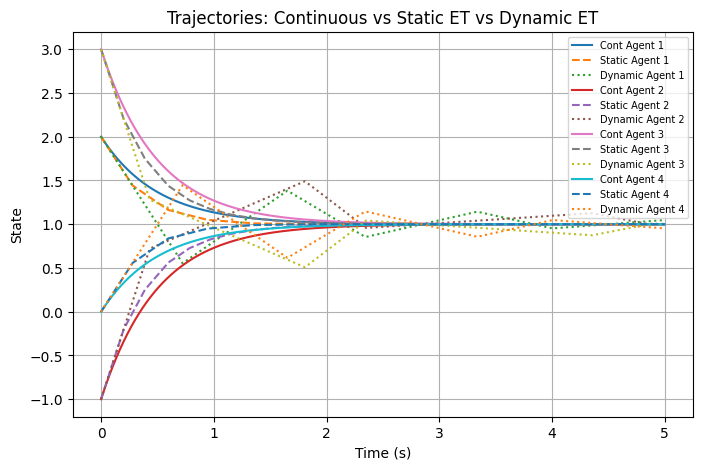

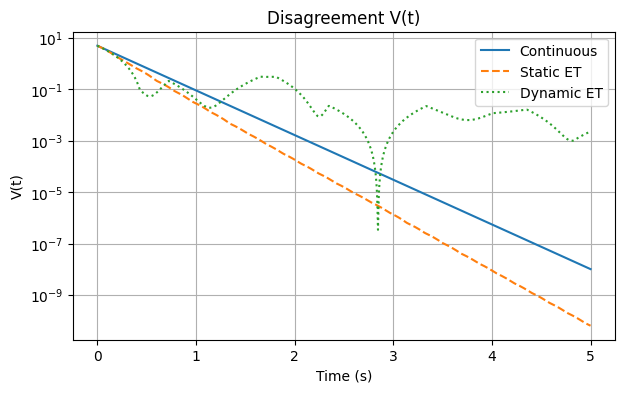

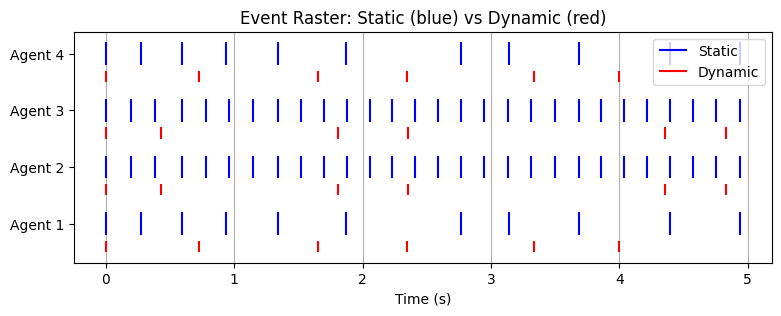

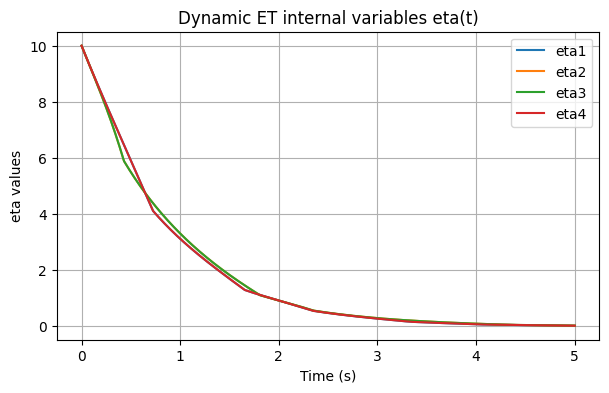

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ===== Parameters =====
n = 4
T = 5.0
dt = 0.001
steps = int(T/dt)
time = np.linspace(0, T, steps+1)

# Graph Laplacian (ring topology)
L = np.array([[ 2, -1, -1,  0],
              [-1,  2,  0, -1],
              [-1,  0,  2, -1],
              [ 0, -1, -1,  2]])
Lii = np.diag(L)

# Initial state
x0 = np.array([2.0, -1.0, 3.0, 0.0])

# ===== Continuous consensus =====
X_cont = np.zeros((steps+1, n))
X_cont[0] = x0
for k in range(steps):
    X_cont[k+1] = X_cont[k] + dt*(-L @ X_cont[k])
V_cont = 0.5 * np.sum((X_cont - X_cont.mean(axis=1, keepdims=True))**2, axis=1)

# ===== Static ET consensus =====
sigma = 0.5
X_stat = np.zeros((steps+1, n))
X_stat[0] = x0
xhat_stat = x0.copy()
triggers_stat = [[] for _ in range(n)]
for i in range(n):
    triggers_stat[i].append(0.0)
V_stat = np.zeros(steps+1)
V_stat[0] = 0.5*np.sum((x0-np.mean(x0))**2)

for k in range(steps):
    x = X_stat[k]
    u = -L @ xhat_stat
    x_next = x + dt*u
    X_stat[k+1] = x_next
    qhat = np.zeros(n)
    for i in range(n):
        s = 0
        for j in range(n):
            dij = xhat_stat[j]-xhat_stat[i]
            s += L[i,j]*(dij**2)
        qhat[i] = max(-0.5*s,0)
    e = xhat_stat - x_next
    for i in range(n):
        rhs = (sigma/(2*Lii[i]))*qhat[i] if Lii[i]>0 else 0
        if e[i]**2 > rhs:
            xhat_stat[i] = x_next[i]
            triggers_stat[i].append(time[k+1])
    V_stat[k+1] = 0.5*np.sum((x_next-np.mean(x_next))**2)

# ===== Dynamic ET consensus =====
beta, xi, theta, eta0 = 1.0, 1.0, 1.0, 10.0
X_dyn = np.zeros((steps+1, n))
X_dyn[0] = x0
xhat_dyn = x0.copy()
eta = np.ones(n)*eta0
eta_hist = np.zeros((steps+1,n))
eta_hist[0] = eta
triggers_dyn = [[] for _ in range(n)]
for i in range(n):
    triggers_dyn[i].append(0.0)
V_dyn = np.zeros(steps+1)
V_dyn[0] = 0.5*np.sum((x0-np.mean(x0))**2)

for k in range(steps):
    x = X_dyn[k]
    u = -L @ xhat_dyn
    x_next = x + dt*u
    X_dyn[k+1] = x_next
    # q from true x
    q = np.zeros(n)
    for i in range(n):
        s = 0
        for j in range(n):
            dij = x[j]-x[i]
            s += L[i,j]*(dij**2)
        q[i] = max(-0.5*s,0)
    e = xhat_dyn - x_next
    # update eta
    for i in range(n):
        eta_dot = -beta*eta[i] + xi*((sigma/2)*q[i] - Lii[i]*(e[i]**2))
        eta[i] += dt*eta_dot
    eta_hist[k+1] = eta
    # trigger check
    for i in range(n):
        cond = theta*(Lii[i]*e[i]**2 - (sigma/2)*q[i]) - eta[i]
        if cond > 0:
            xhat_dyn[i] = x_next[i]
            triggers_dyn[i].append(time[k+1])
    V_dyn[k+1] = 0.5*np.sum((x_next-np.mean(x_next))**2)

# ====== Trigger statistics ======
def stats(trigs):
    out = []
    for i in range(n):
        times = np.diff(trigs[i]) if len(trigs[i])>1 else []
        avg = np.mean(times) if len(times)>0 else None
        out.append((len(trigs[i]), avg))
    return out

print("Static ET triggers:", stats(triggers_stat))
print("Dynamic ET triggers:", stats(triggers_dyn))

# ===== Plots =====
# Trajectories
plt.figure(figsize=(8,5))
for i in range(n):
    plt.plot(time, X_cont[:,i], label=f"Cont Agent {i+1}")
    plt.plot(time, X_stat[:,i], '--', label=f"Static Agent {i+1}")
    plt.plot(time, X_dyn[:,i], ':', label=f"Dynamic Agent {i+1}")
plt.xlabel("Time (s)"); plt.ylabel("State")
plt.title("Trajectories: Continuous vs Static ET vs Dynamic ET")
plt.legend(fontsize=7, loc="best"); plt.grid(True); plt.show()

# Disagreement V(t)
plt.figure(figsize=(7,4))
plt.plot(time, V_cont, label="Continuous")
plt.plot(time, V_stat, '--', label="Static ET")
plt.plot(time, V_dyn, ':', label="Dynamic ET")
plt.yscale("log")
plt.xlabel("Time (s)"); plt.ylabel("V(t)"); plt.title("Disagreement V(t)")
plt.legend(); plt.grid(True, which="both"); plt.show()

# Event raster
plt.figure(figsize=(9,3))
for i in range(n):
    plt.vlines(triggers_stat[i], i+0.8, i+1.2, color="blue", label="Static" if i==0 else "")
    plt.vlines(triggers_dyn[i], i+0.5, i+0.7, color="red", label="Dynamic" if i==0 else "")
plt.yticks(range(1,n+1), [f"Agent {i+1}" for i in range(n)])
plt.xlabel("Time (s)"); plt.title("Event Raster: Static (blue) vs Dynamic (red)")
plt.legend(); plt.grid(True, axis="x"); plt.show()

# Eta dynamics
plt.figure(figsize=(7,4))
for i in range(n):
    plt.plot(time, eta_hist[:,i], label=f"eta{i+1}")
plt.xlabel("Time (s)"); plt.ylabel("eta values")
plt.title("Dynamic ET internal variables eta(t)")
plt.legend(); plt.grid(True); plt.show()
